In [1]:
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path
from pypalettes import load_cmap


In [2]:
current_path = Path.cwd()
project_root = next(
    (
        path
        for path in (current_path, *current_path.parents)
        if (path / "data" / "raw" / "listings.csv").is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the project root containing data/raw/listings.csv")

df = pd.read_csv(project_root / "data" / "raw" / "listings.csv")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

sys.path.append(str(project_root))   
from src.cleaning import basic_clean

cmap = load_cmap('CarolMan')


['host_is_superhost', 'neighbourhood_cleansed', 'is_house', 'accommodates', 'bedrooms', 'price', 'minimum_nights', 'bathrooms', 'has_rating', 'weighted_rating', 'log_price', 'minimum_nights_log', 'neighbourhood_grouped', 'dummy_Bjerke', 'dummy_Frogner', 'dummy_Gamle_Oslo', 'dummy_Grünerløkka', 'dummy_Nordre_Aker', 'dummy_Nordstrand', 'dummy_Sagene', 'dummy_St._Hanshaugen', 'dummy_Stovner/Grorud/Alna', 'dummy_Søndre_Nordstrand', 'dummy_Ullern', 'dummy_Vestre_Aker', 'dummy_Østensjø']


In [3]:
#doing the basic clean to look at relationships between variables for listing we will actually use
df_c = basic_clean(df)

columns = pd.DataFrame({
    "Column": df_c.columns,
    "Data type": df_c.dtypes.astype(str).values,
    "Unique values": df_c.nunique(dropna=True).values,
    "NaN values": df_c.isna().sum().values,
    })

print(columns)

                    Column Data type  Unique values  NaN values
0   neighbourhood_cleansed       str             17           0
1                 latitude   float64           6028           0
2                longitude   float64           6550           0
3                 is_house     int64              2           0
4             accommodates     int64             16           0
5                 bedrooms   float64              8           0
6                     beds   float64             12         149
7          price_per_night   float64           4376           0
8                bathrooms   float64              8           0
9                 n_nights     int64             25           0
10        days_til_checkin     int64            282           0
11           checkin_month     int32             12           0


### Price
log price gives a more symmetric distribution and weights the more expensive listings less, good for linear regression

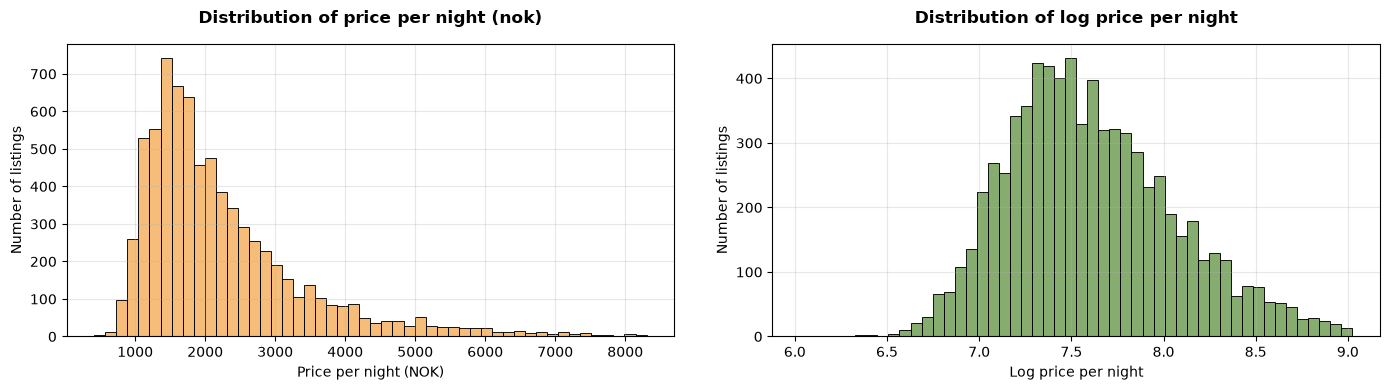

In [4]:
df_c['log_price'] = np.log(df_c['price_per_night'])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plots = [('price_per_night', 'Price per night (NOK)'),
         ('log_price', 'Log price per night')]

for i, (ax, (var, label)) in enumerate(zip(axes, plots)):
    sns.histplot(data=df_c, x=var, bins=50, color=cmap(i+1), alpha=0.7, ax=ax)
    ax.set_title(f'Distribution of {label.lower()}', weight='bold', pad=15)
    ax.set_xlabel(label)
    ax.set_ylabel('Number of listings')
    ax.grid(alpha=0.3)

plt.tight_layout(w_pad=3)
plt.show()


### Location latitude and longitude
Not surrisingly, the more expensive regions aree near the city centre, however when we look by property type we see that it is to some extent because there are more houses there
not sure if it is needed for the models as it provides similiar information as neighbourhoods

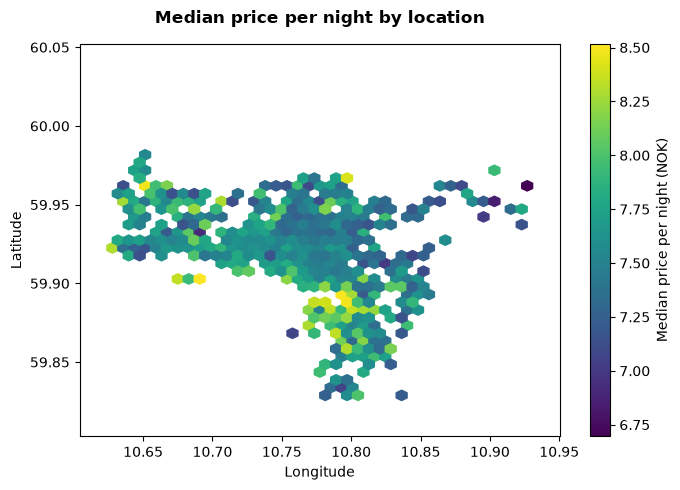

In [5]:
#looking a location in terms of lattitude and longitude
fig, ax = plt.subplots(figsize=(7, 5))

hb = ax.hexbin(df_c['longitude'], df_c['latitude'], C=df_c['log_price'],
               reduce_C_function=np.median,   # median price in each hexagon
               gridsize=40,                   # higher = smaller hexagons
               mincnt=3,                      # only show hexagons with at least 3 listings
               cmap='viridis')

fig.colorbar(hb, ax=ax, label='Median price per night (NOK)')
ax.set_title('Median price per night by location', weight='bold', pad=15)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.tight_layout()
plt.show()


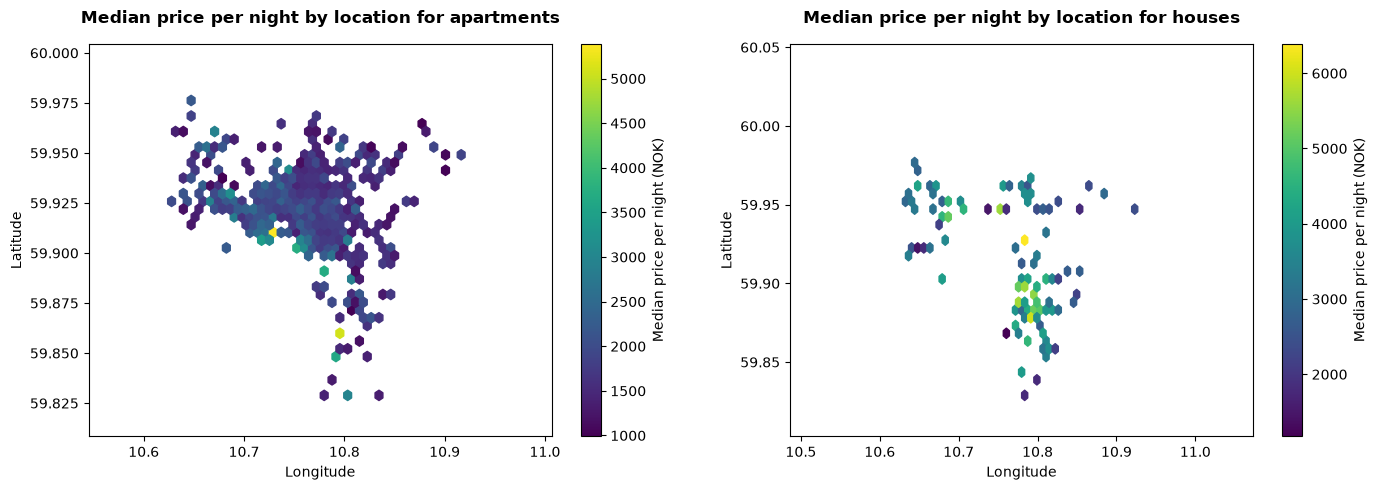

In [6]:
#diving by is house and is not house to see the effect on the map
labels = {0: 'apartments', 1: 'houses'}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i in range(2):
    subset = df_c[df_c['is_house'] == i]
    ax = axes[i]
    hb = ax.hexbin(subset['longitude'], subset['latitude'], C=subset['price_per_night'],
                   reduce_C_function=np.median,
                   gridsize=40,
                   mincnt=3,
                   cmap='viridis')
    fig.colorbar(hb, ax=ax, label='Median price per night (NOK)')
    ax.set_aspect(1 / np.cos(np.radians(df_c['latitude'].mean())), adjustable='datalim')
    ax.set_title(f'Median price per night by location for {labels[i]}', weight='bold', pad=15)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
plt.tight_layout(w_pad=3)

### Neighbourhood 
we can see that some neighbourhoods are generally more expensive<br>
if we do one city model and one distric model we would have to group together some neighbourhoods since they have to few listings <br>
marka might have to be dropped considering it is a really different terrain than the other districts so it cannot be merged <br>
need to make dummies for linear regression

/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


neighbourhood_cleansed
Grünerløkka          1417
Gamle Oslo           1280
Frogner              1115
St. Hanshaugen        870
Sagene                794
Nordstrand            348
Nordre Aker           282
Vestre Aker           248
Ullern                228
Østensjø              189
Bjerke                184
Sentrum               138
Alna                  116
Søndre Nordstrand      83
Grorud                 43
Stovner                30
Marka                  28
Name: count, dtype: int64


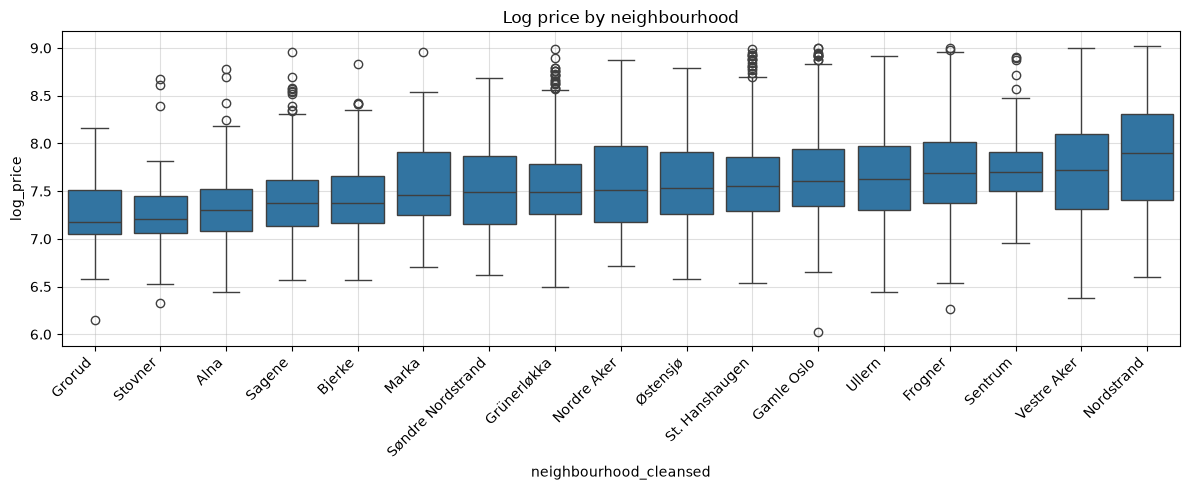

In [7]:
order = df_c.groupby("neighbourhood_cleansed")["log_price"].median().sort_values().index

plt.figure(figsize=(12, 5))
sns.boxplot(data=df_c, x="neighbourhood_cleansed", y="log_price", order=order)
plt.xticks(rotation=45, ha="right")
plt.title("Log price by neighbourhood")
plt.tight_layout()
plt.grid(alpha = 0.4)

print(df_c["neighbourhood_cleansed"].value_counts())   # check group sizes

/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


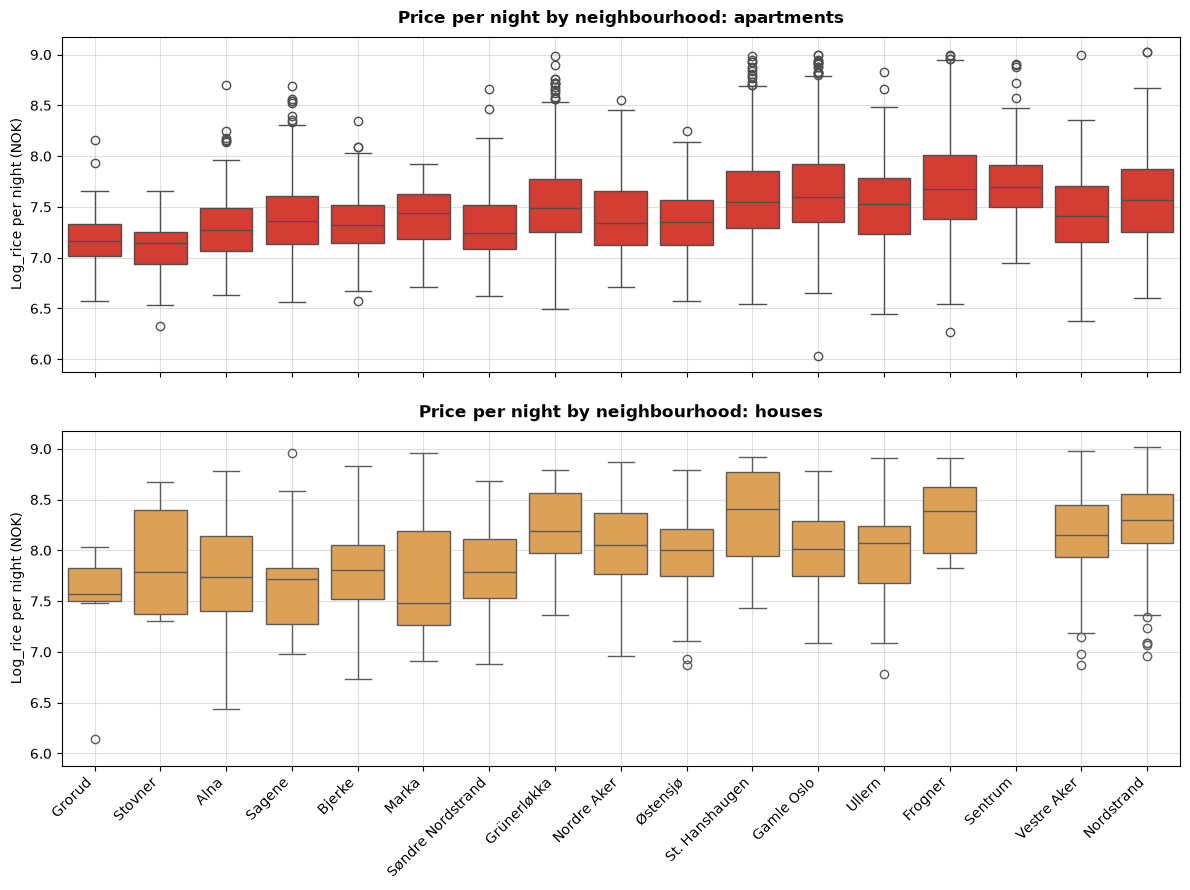

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True, sharey=True)

for i, ax in enumerate(axes):
    subset = df_c[df_c['is_house'] == i]
    sns.boxplot(data=subset, x="neighbourhood_cleansed", y="log_price",
                order=order, color=cmap(i), showfliers=True, ax=ax)
    ax.set_title(f"Price per night by neighbourhood: {labels[i].lower()}", weight='bold', pad=10)
    ax.set_xlabel("")
    ax.set_ylabel("Log_rice per night (NOK)")
    ax.grid(alpha=0.4)

axes[1].tick_params(axis='x', labelrotation=45)
plt.setp(axes[1].get_xticklabels(), ha='right')
plt.tight_layout(h_pad= 2)
plt.show()

### Property details
we see that bedrooms differentiates prices per night within the same value for accomodates, something beds does not do, therefore drop beds from dataframe for modelleing
drop listing with 13 accomodates because it is kind of weird <br>
The listings with more than 12 accomodations have very few listings and a weird behaviour in terms of beds, bedrooms and bathrooms, drop these


/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/matrix.py:243: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  self.cmap.set_bad(bad)


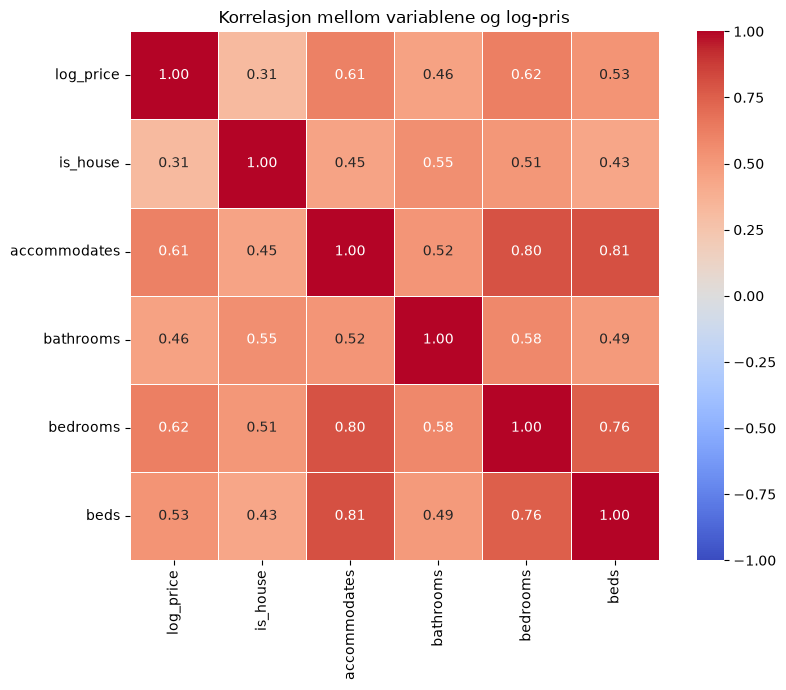

In [9]:
heatmap_columns = [
    'log_price', 'is_house', 'accommodates', 'bathrooms',
    'bedrooms', 'beds'
]

correlation_matrix = df_c[heatmap_columns].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1, center=0,
    linewidths=0.5,
    square=True,
)
plt.title("Korrelasjon mellom variablene og log-pris")
plt.tight_layout()
plt.show()

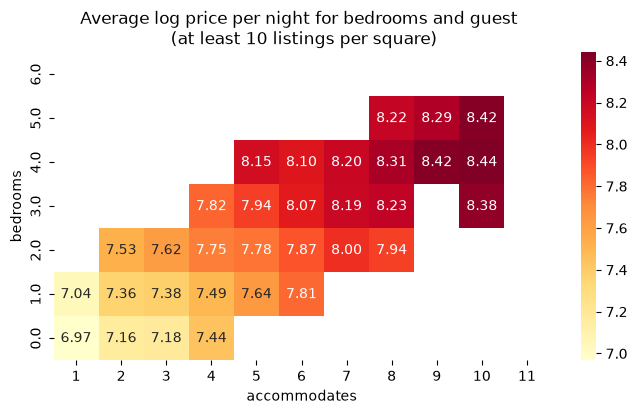

In [10]:
#look at correlation between beds/bedrooms and accomodates. Look if adding one of them differentiates the price
pivot_mean = df_c.pivot_table(index="bedrooms", columns="accommodates",
                                  values="log_price", aggfunc="mean")
pivot_count = df_c.pivot_table(index="bedrooms", columns="accommodates",
                                   values="price_per_night", aggfunc="count")

plt.figure(figsize=(8, 4))
ax = sns.heatmap(pivot_mean.where(pivot_count >= 10),
                 annot=True, fmt=".2f", cmap="YlOrRd")
ax.invert_yaxis()   # flere soverom oppover
ax.set_xlim(0, 11)
ax.set_ylim(0, 7)
plt.title("Average log price per night for bedrooms and guest \n (at least 10 listings per square)")
plt.show()


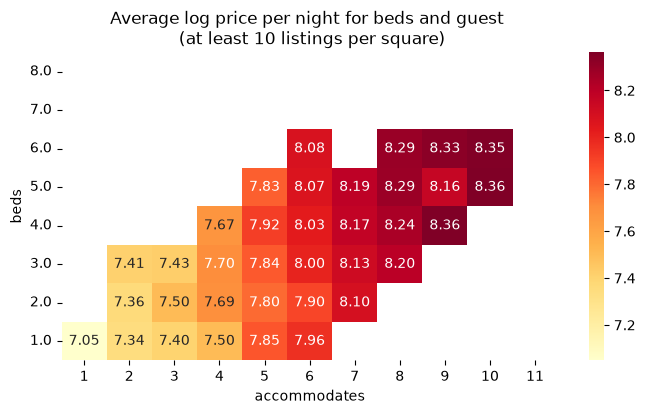

In [11]:
pivot_mean = df_c.pivot_table(index="beds", columns="accommodates",
                                  values="log_price", aggfunc="mean")
pivot_count = df_c.pivot_table(index="beds", columns="accommodates",
                                   values="log_price", aggfunc="count")

plt.figure(figsize=(8, 4))
ax = sns.heatmap(pivot_mean.where(pivot_count >= 10),
                 annot=True, fmt=".2f", cmap="YlOrRd")
ax.invert_yaxis()   # flere soverom oppover
ax.set_xlim(0, 11)
ax.set_ylim(0, 8)
plt.title("Average log price per night for beds and guest \n (at least 10 listings per square)")
plt.show()

/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_

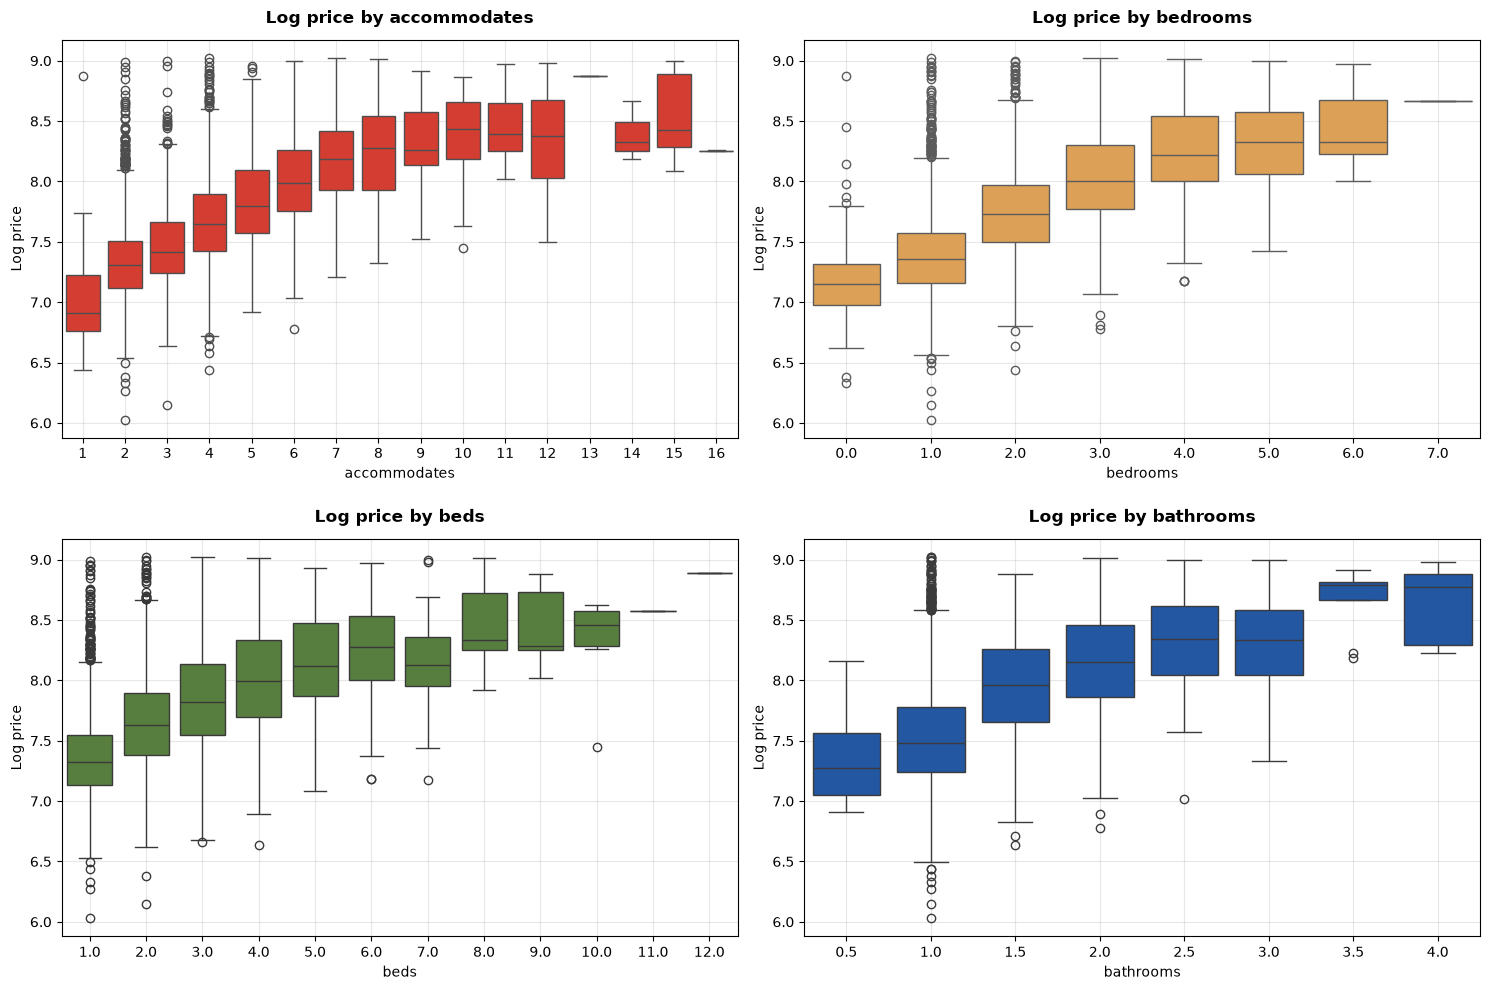

In [32]:
 
numeric_columns = ['accommodates', 'bedrooms', 'beds', 'bathrooms']

columns_per_row = 2
rows = (len(numeric_columns) + columns_per_row - 1) // columns_per_row
fig, axes = plt.subplots(rows, columns_per_row, figsize=(15, 5 * rows), squeeze=False)
axes = axes.flatten()

for i, (ax, column) in enumerate(zip(axes, numeric_columns)):
    sns.boxplot(data=df_c, x=column, y="log_price", color=cmap(i % cmap.N), ax=ax)
    ax.set_title(f"Log price by {column}", fontweight="bold", pad=12)
    ax.set_xlabel(column)
    ax.set_ylabel("Log price")
    ax.grid(alpha=0.3)

for ax in axes[len(numeric_columns):]:
    ax.remove()

plt.tight_layout(h_pad=2.0)


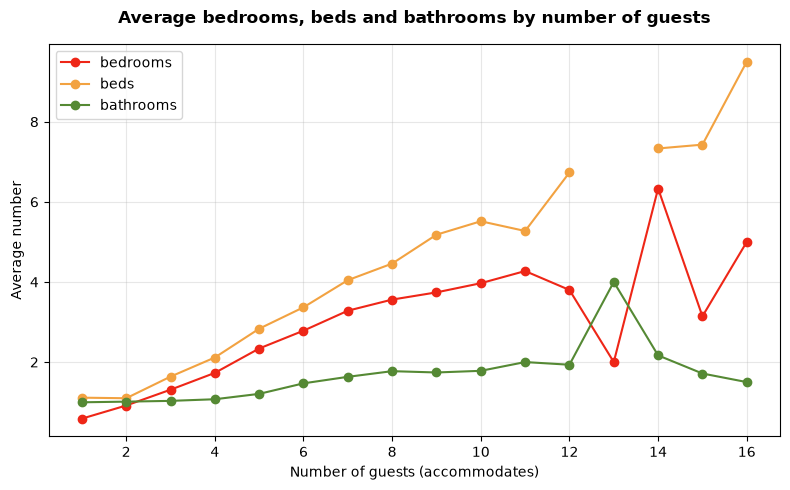

In [33]:
avg = df_c.groupby('accommodates')[['bedrooms', 'beds', 'bathrooms']].mean()

fig, ax = plt.subplots(figsize=(8, 5))
for i, col in enumerate(avg.columns):
    ax.plot(avg.index, avg[col], marker='o', color=cmap(i), label=col)

ax.set_title('Average bedrooms, beds and bathrooms by number of guests', weight='bold', pad=15)
ax.set_xlabel('Number of guests (accommodates)')
ax.set_ylabel('Average number')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [34]:
print(df_c['accommodates'].value_counts().sort_index())


accommodates
1      109
2     2469
3      953
4     2135
5      585
6      624
7      156
8      209
9       50
10      64
11      11
12      15
13       1
14       3
15       7
16       2
Name: count, dtype: int64


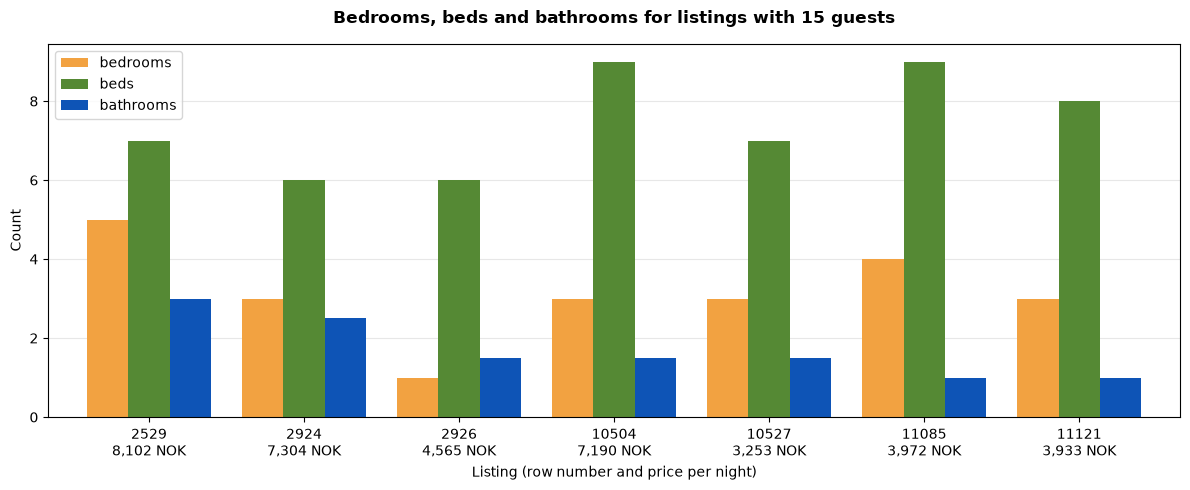

In [36]:
cols = ['bedrooms', 'beds', 'bathrooms']
big = df_c[df_c['accommodates'] == 15]

fig, ax = plt.subplots(figsize=(12, 5))
big[cols].plot(kind='bar', ax=ax, color=[cmap(i+1) for i in range(len(cols))], width=0.8)

# label each listing with its row number and price
ax.set_xticklabels([f'{idx}\n{price:,.0f} NOK' for idx, price in zip(big.index, big['price_per_night'])],
                   rotation=0)

ax.set_title('Bedrooms, beds and bathrooms for listings with 15 guests', weight='bold', pad=15)
ax.set_xlabel('Listing (row number and price per night)')
ax.set_ylabel('Count')
ax.legend(title='')
ax.grid(alpha=0.3, axis='y')
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


### House or apartment

/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


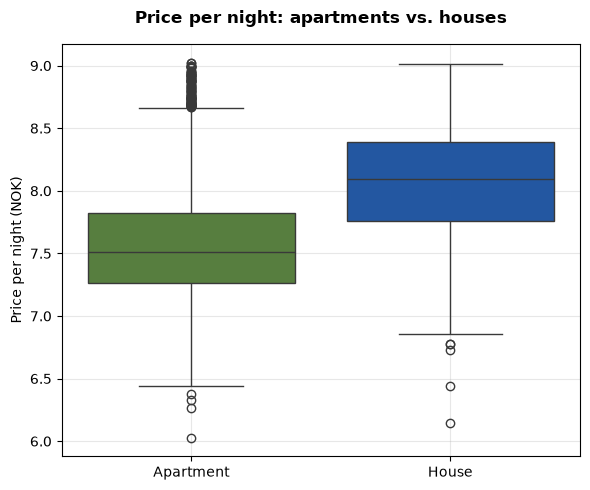

In [12]:
fig, ax = plt.subplots(figsize=(6, 5))

sns.boxplot(data=df_c, x='is_house', y='log_price',
            hue='is_house', palette={0: cmap(2), 1: cmap(3)},
            legend=False, ax=ax)

ax.set_xticks([0, 1])
ax.set_xticklabels(['Apartment', 'House'])
ax.set_title('Price per night: apartments vs. houses', weight='bold', pad=15)
ax.set_ylabel('Price per night (NOK)')
ax.set_xlabel('')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


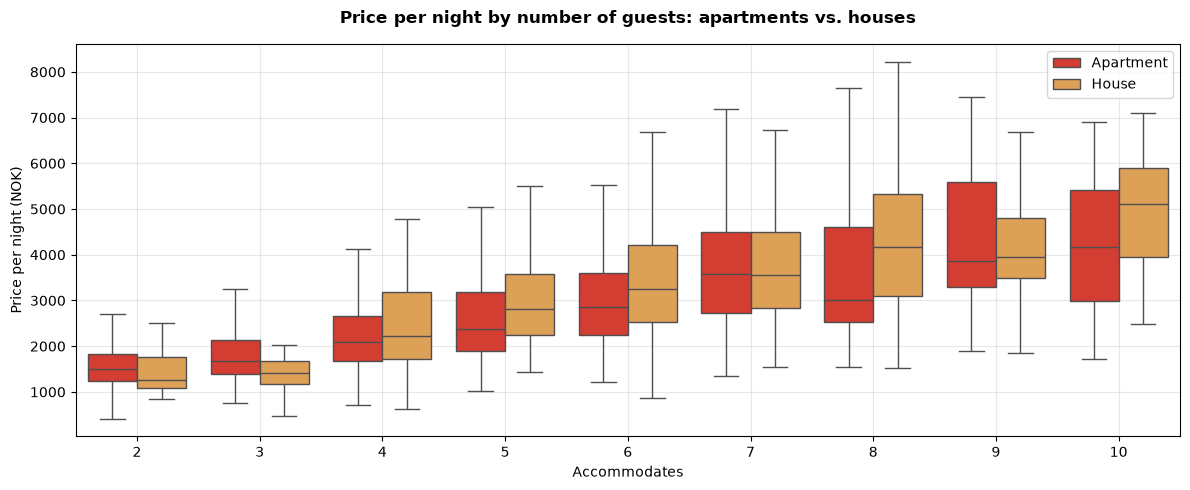

In [13]:
subset = df_c[df_c['accommodates'].between(2, 10)]   # enough houses in each group

fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=subset, x='accommodates', y='price_per_night', hue='is_house',
            palette={0: cmap(0), 1: cmap(1)}, showfliers=False, ax=ax)

handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ['Apartment', 'House'])
ax.set_title('Price per night by number of guests: apartments vs. houses', weight='bold', pad=15)
ax.set_xlabel('Accommodates')
ax.set_ylabel('Price per night (NOK)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Date of booking
Diffuclt, while which month the booking is in is quite important as prices tend to increase in summer months or around christmas, the fact that some of these bookings were done on extreme short notice makes sempetmber seem like an expensive month. If going more in depht one would have to add more data from a different scrape date, but in this case we decide to drop which month. Also each month is based on very different amount of data so they are hard to compare without taking othe rfactors into account

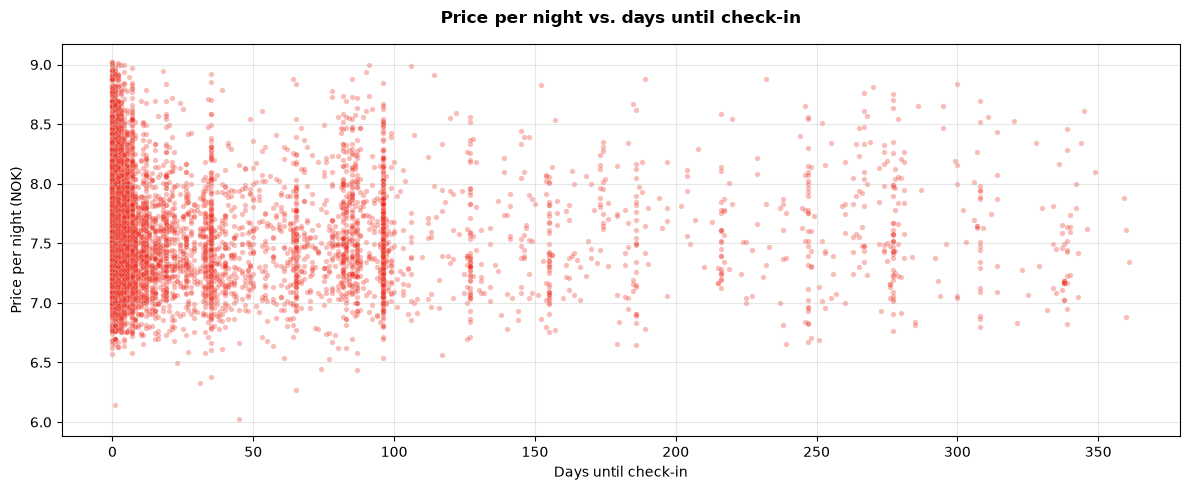

In [14]:
fig, ax = plt.subplots(figsize=(12, 5))

sns.scatterplot(data=df_c, x='days_til_checkin', y='log_price',
                color=cmap(0), alpha=0.3, s=15, ax=ax)

ax.set_title('Price per night vs. days until check-in', weight='bold', pad=15)
ax.set_xlabel('Days until check-in')
ax.set_ylabel('Price per night (NOK)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


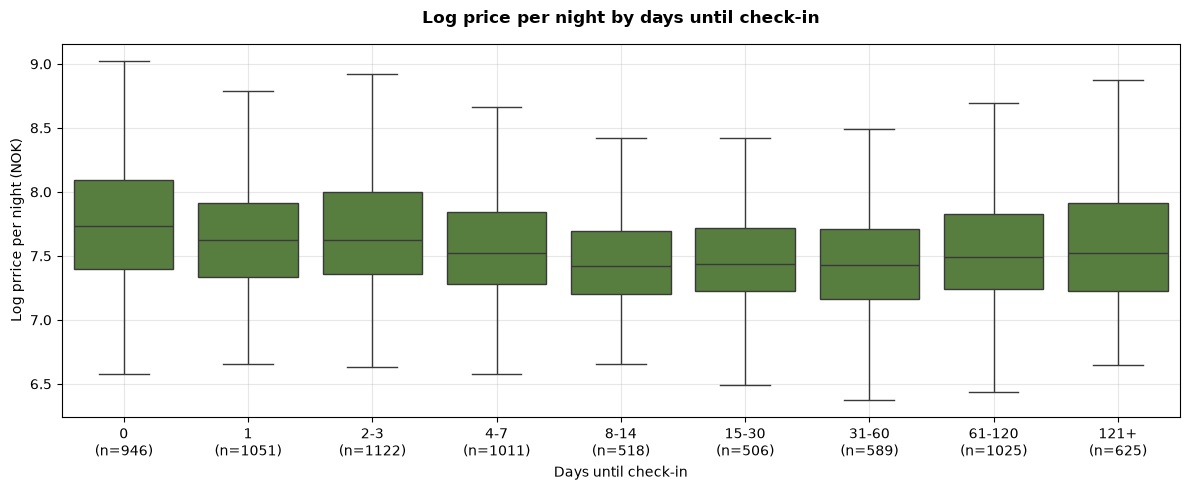

In [20]:
bins = [-1, 0, 1, 3, 7, 14, 30, 60, 120, 400]
labels = ['0', '1', '2-3', '4-7', '8-14', '15-30', '31-60', '61-120', '121+']
days_group = pd.cut(df_c['days_til_checkin'], bins=bins, labels=labels)
counts = days_group.value_counts().reindex(labels)

fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot( x=days_group, y=df_c['log_price'],
            color=cmap(2), showfliers=False, ax=ax)

# number of listings under each box
ax.set_xticks(range(len(labels)))
ax.set_xticklabels([f'{l}\n(n={counts[l]})' for l in labels])

ax.set_title('Log price per night by days until check-in', weight='bold', pad=15)
ax.set_xlabel('Days until check-in')
ax.set_ylabel('Log prrice per night (NOK)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


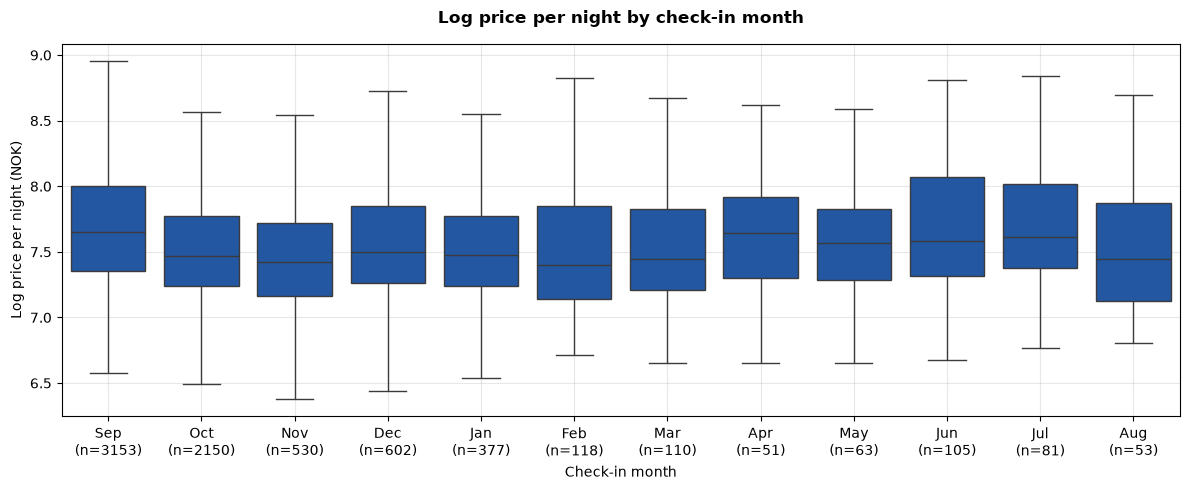

In [23]:
month_order = [9, 10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8]
month_names = ['Sep', 'Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug']
counts = df_c['checkin_month'].value_counts().reindex(month_order, fill_value=0)

fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df_c, x='checkin_month', y='log_price', order=month_order,
            color=cmap(3), showfliers=False, ax=ax)

# month names with number of listings under each box
ax.set_xticks(range(len(month_order)))
ax.set_xticklabels([f'{name}\n(n={counts[m]})' for name, m in zip(month_names, month_order)])

ax.set_title('Log price per night by check-in month', weight='bold', pad=15)
ax.set_xlabel('Check-in month')
ax.set_ylabel('Log price per night (NOK)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


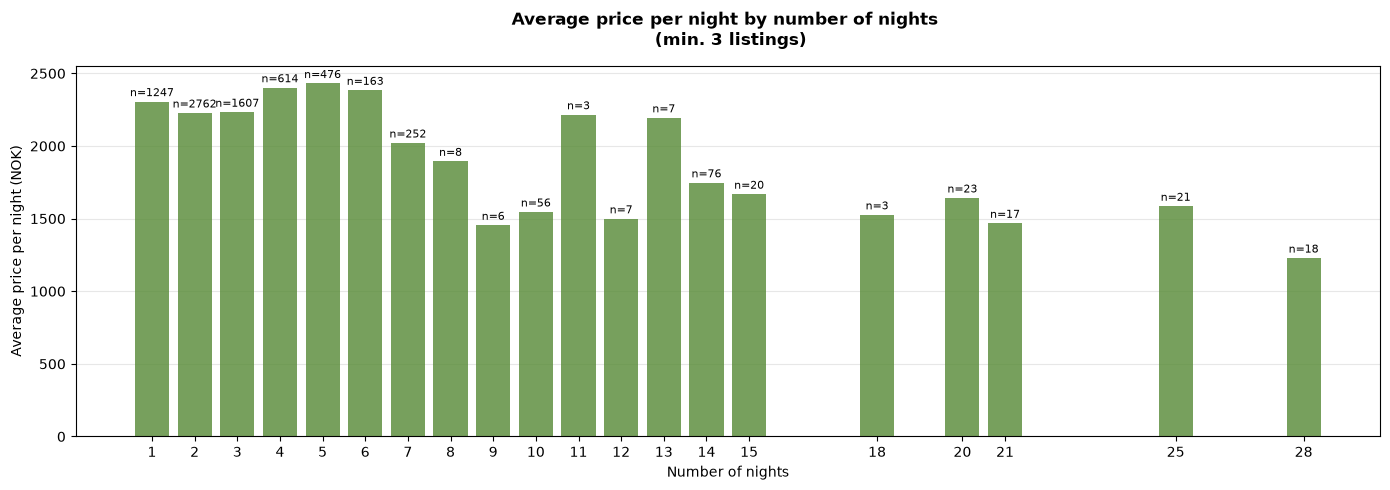

In [28]:
avg_price = df_c.groupby('n_nights')['price_per_night'].mean()
counts = df_c['n_nights'].value_counts().sort_index()

# keep only numbers of nights with at least 3 listings
keep = counts[counts >= 3].index
avg_price = avg_price.loc[keep]

fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(avg_price.index, avg_price.values, color=cmap(2), alpha=0.8)

# number of listings above each bar
ax.bar_label(bars, labels=[f'n={counts[n]}' for n in avg_price.index], fontsize=8, padding=2)

ax.set_xticks(avg_price.index)
ax.set_title('Average price per night by number of nights \n (min. 3 listings)', weight='bold', pad=15)
ax.set_xlabel('Number of nights')
ax.set_ylabel('Average price per night (NOK)')
ax.grid(alpha=0.3, axis='y')
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()



### All together
looking at heatmap of all numeric features with log price as target <br>
looking at possible transformations for linear regression models, going to decide which to kee


In [39]:
df_c['accommodates'] = df_c['accommodates'].clip(upper=12)
df_c = df_c.drop(columns = ['beds', 'checkin_month'])

/Users/malenalisken/Documents/MAMO/DATA3800_Datascience_Scripting/Airbnb_project/.venv/lib/python3.13/site-packages/seaborn/matrix.py:243: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  self.cmap.set_bad(bad)


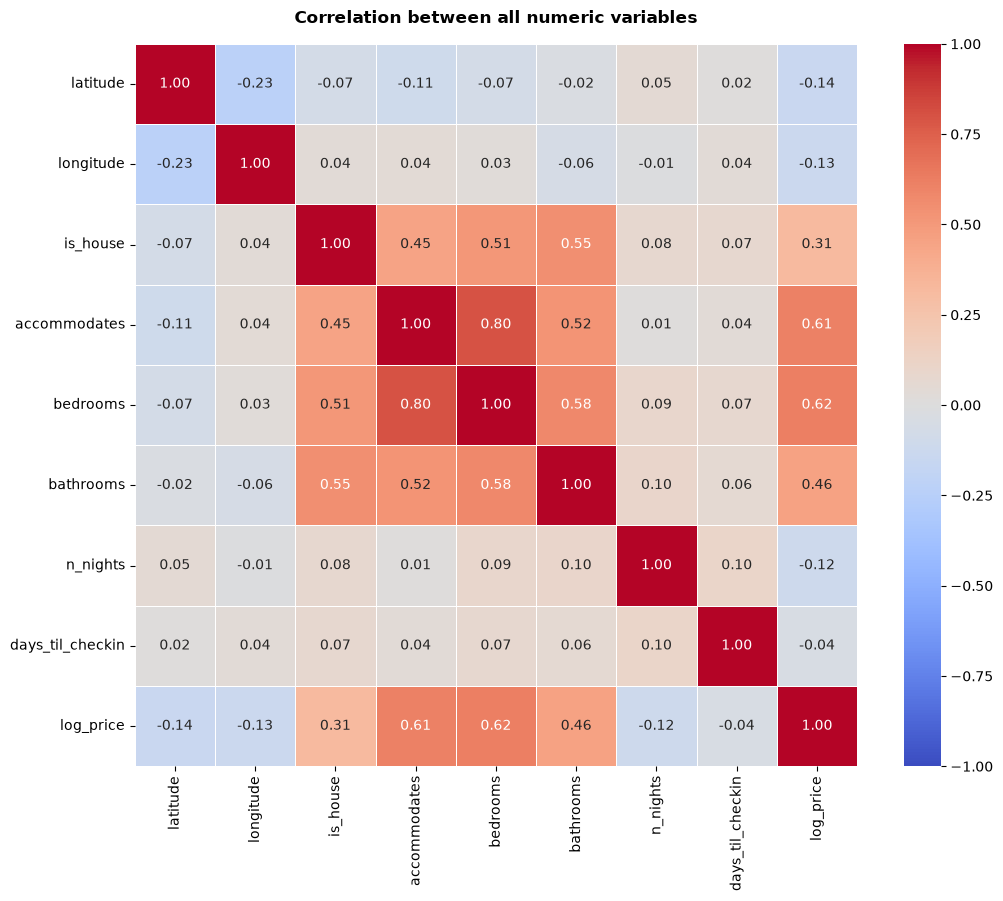

In [41]:
numeric_df = df_c.select_dtypes('number').drop(columns=['price_per_night'])
correlation_matrix = numeric_df.corr()


fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1, center=0,
    linewidths=0.5,
    square=True,
    ax=ax,
)
ax.set_title("Correlation between all numeric variables", weight='bold', pad=15)
plt.tight_layout()
plt.show()


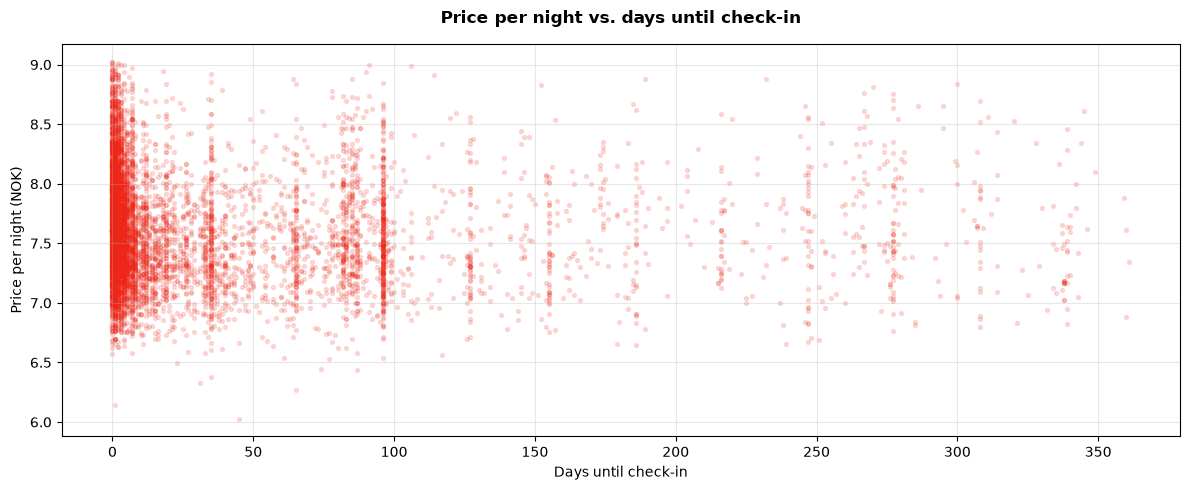

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.scatter(df_c['days_til_checkin'], df_c['log_price'],
           color=cmap(0), alpha=0.15, s=8)

ax.set_title('Log price per night vs. days until check-in', weight='bold', pad=15)
ax.set_xlabel('Days until check-in')
ax.set_ylabel('Log price per night (NOK)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


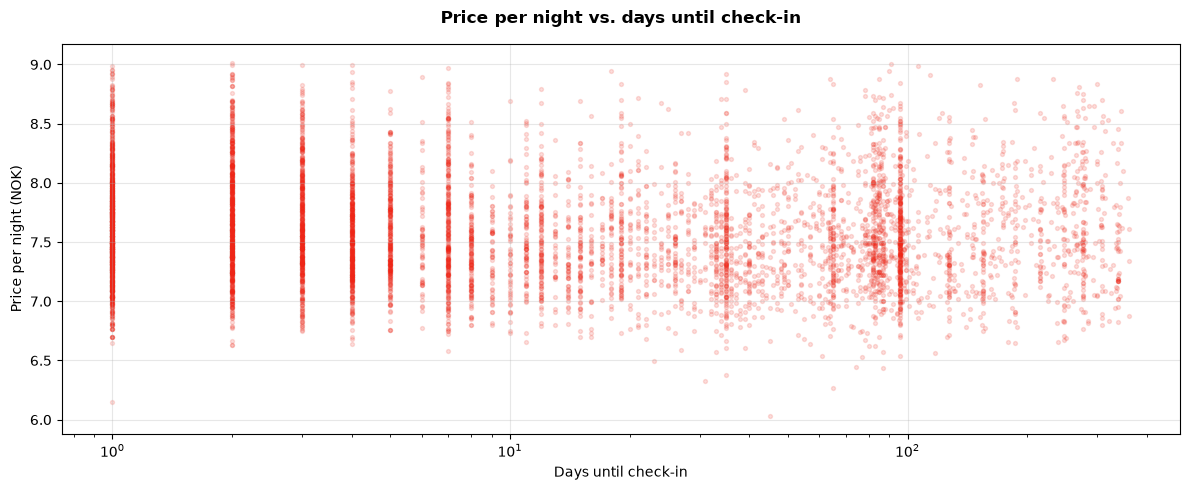

In [ ]:
#the price is likely to drop a lot once it is not as much of a shorterm booking
fig, ax = plt.subplots(figsize=(12, 5))

ax.scatter(df_c['days_til_checkin'], df_c['log_price'],
           color=cmap(0), alpha=0.15, s=8)

ax.set_title('Price per night vs. days until check-in', weight='bold', pad=15)
ax.set_xlabel('Days until check-in')
ax.set_ylabel('Price per night (NOK)')
ax.set_xscale('log')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

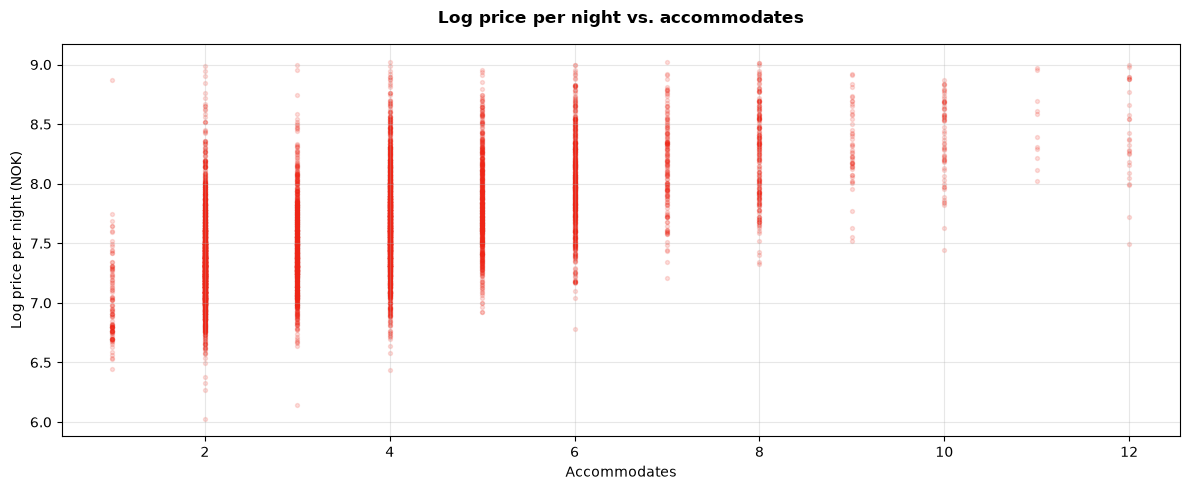

In [53]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.scatter(df_c['accommodates'], df_c['log_price'],
           color=cmap(0), alpha=0.15, s=8)

ax.set_title('Log price per night vs. accommodates', weight='bold', pad=15)
ax.set_xlabel('Accommodates')
ax.set_ylabel('Log price per night (NOK)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

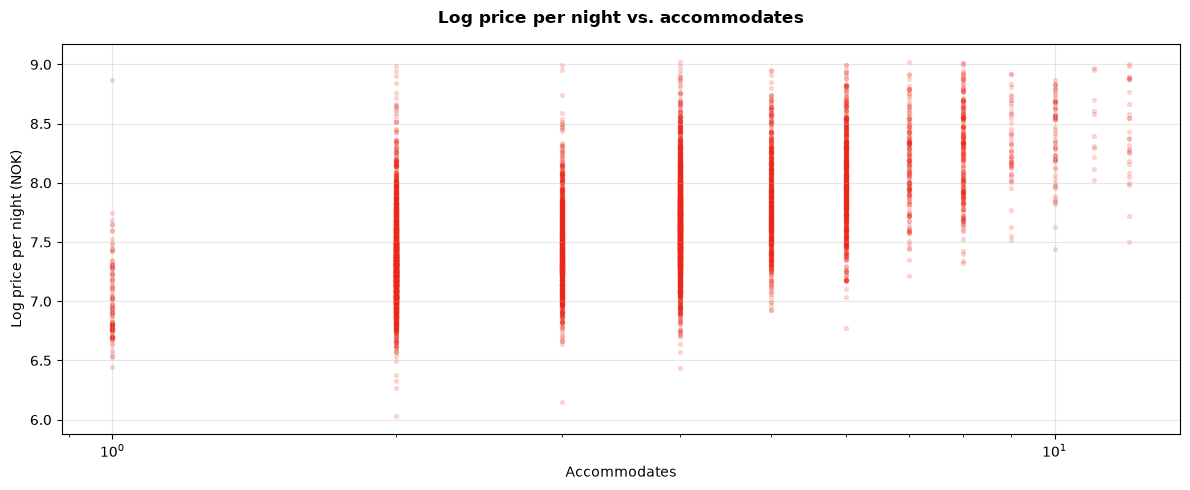

In [54]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.scatter(df_c['accommodates'], df_c['log_price'],
           color=cmap(0), alpha=0.15, s=8)

ax.set_title('Log price per night vs. accommodates', weight='bold', pad=15)
ax.set_xlabel('Accommodates')
ax.set_ylabel('Log price per night (NOK)')
ax.set_xscale('log')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

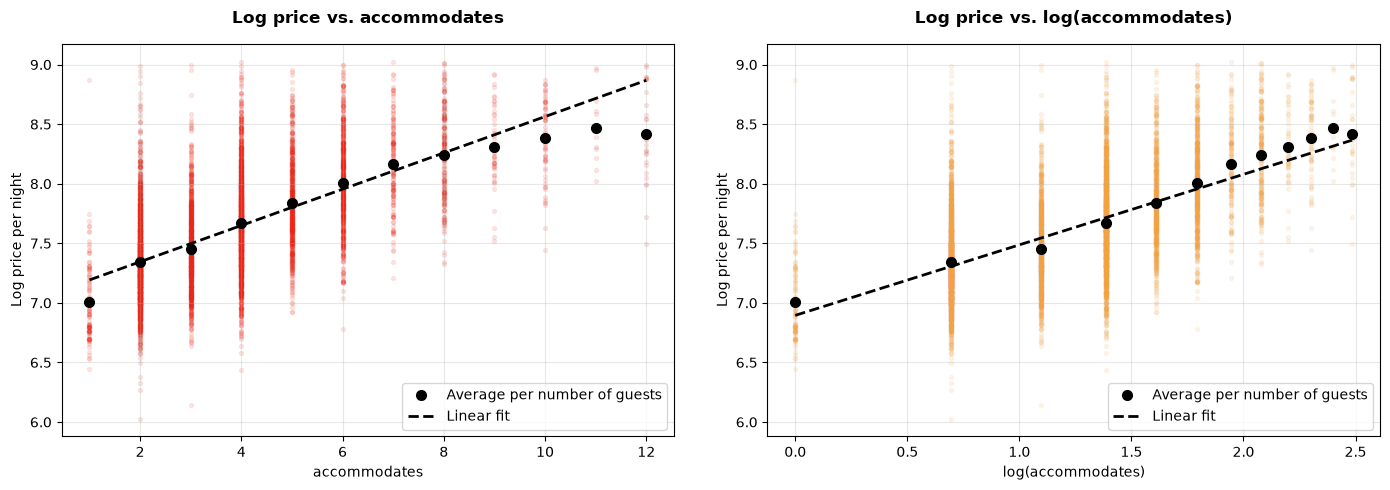

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
versions = [('accommodates', df_c['accommodates']),
            ('log(accommodates)', np.log(df_c['accommodates']))]
y = df_c['log_price']

# average log price per number of guests (min. 5 listings)
avg = y.groupby(df_c['accommodates']).agg(['mean', 'count'])
avg = avg[avg['count'] >= 5]

for i, (ax, (label, x)) in enumerate(zip(axes, versions)):
    ax.scatter(x, y, color=cmap(i), alpha=0.1, s=8)

    # averages, placed on the same x scale as the plot
    x_avg = avg.index if i == 0 else np.log(avg.index)
    ax.plot(x_avg, avg['mean'], 'o', color='black', markersize=7, label='Average per number of guests')

    # straight line that linear regression would fit
    slope, intercept = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, intercept + slope * xs, color='black', linestyle='--', linewidth=2, label='Linear fit')

    ax.set_title(f'Log price vs. {label}', weight='bold', pad=15)
    ax.set_xlabel(label)
    ax.set_ylabel('Log price per night')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout(w_pad=3)
plt.show()


In [58]:
nan_counts = df_c.isna().sum()
print(nan_counts[nan_counts > 0])           # only columns with missing values
print('Total NaN values:', nan_counts.sum())


Series([], dtype: int64)
Total NaN values: 0
